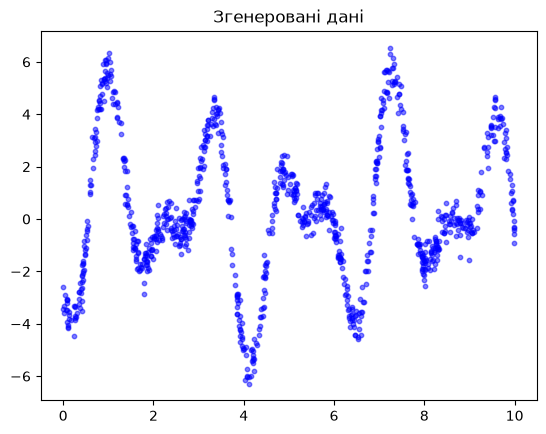

In [17]:
import random
import matplotlib.pyplot as plt
import numpy as np

n=1000

x = np.random.uniform(0, 10, n)

y = np.sin(x) - 3*np.cos(3*x) + 2*np.sin(5*x-3.14) + np.random.normal(0, 0.4, n)

sort_indices = np.argsort(x)
x_sorted = x[sort_indices]
y_sorted = y[sort_indices]

plt.scatter(x, y, alpha=0.5, s=10, c='blue')
plt.title("Згенеровані дані")
plt.show()

In [18]:
def normalize(q):
    minV=min(q)
    maxV=max(q)
    q=(q - minV)/(maxV-minV)
    return q

x=normalize(x_sorted)

x = x.tolist()
y = y_sorted.tolist()

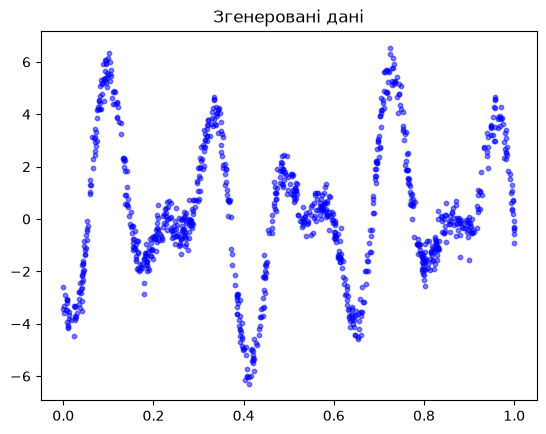

In [19]:
plt.scatter(x, y, alpha=0.5, s=10, c='blue')
plt.title("Згенеровані дані")
plt.show()

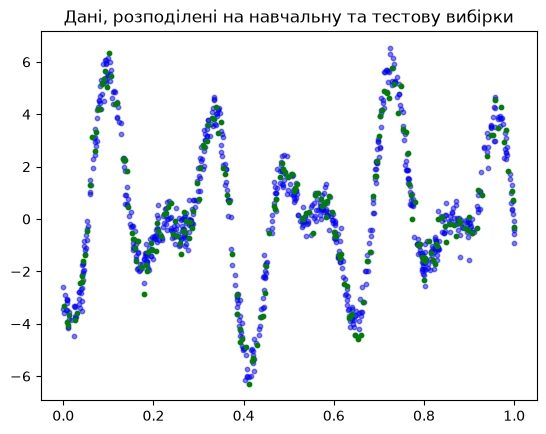

200 800


In [20]:
xLearn,yLearn=[],[]
xTest,yTest=[],[]
for k in range(len(x)):
    if ((k-2)%5==0):
        xTest.append(x[k])
        yTest.append(y[k])
    else:
        xLearn.append(x[k])
        yLearn.append(y[k])
plt.scatter(xLearn, yLearn, alpha=0.5, s=10, c='blue')
plt.scatter(xTest, yTest, s=10, c='green')
plt.title("Дані, розподілені на навчальну та тестову вибірки")
plt.show()

print(len(xTest),len(xLearn))

In [21]:
def knn(x,y,k,xi):
    lens=[]
    for i in range(len(x)):
        lens.append(abs(xi-x[i]))
    ind = lens.index(min(lens))
    indL,indR=ind,ind
    indexNears=[ind]
    for i in range(k-1):
        if (indL<=0):
            indR+=1
            indexNears.append(indR)
        elif (indR>=len(x)-1):
            indL-=1
            indexNears.append(indL)
        else:
            if (lens[indL-1]<lens[indR+1]):
                indL-=1
                indexNears.append(indL)
            else:
                indR+=1
                indexNears.append(indR)
    sumY=0
    for i in range(len(indexNears)):
        sumY+=y[indexNears[i]]
    return sumY/len(indexNears)
    
def knnArray(x,y,k,xNew):
    yNew = []
    for i in range(len(xNew)):
        yNew.append(knn(x,y,k,xNew[i]))
    return yNew

def SStot(y):
    s=0
    yMean=sum(y)/len(y)
    for k in range(len(y)):
        s+=(y[k]-yMean)**2
    return s

def SSres(y,yNew):
    s=0
    for k in range(len(y)):
        s+=(y[k]-yNew[k])**2
    return s

def R2(sstot,yNew,y):
    return 1-(SSres(y,yNew)/sstot)
    

In [28]:
def showGraph(xL,yL,xT,yN,k,r2):
    plt.figure(figsize=(8, 4))
    plt.scatter(xLearn, yLearn, color='black', alpha=0.6)
    plt.plot(xTest, yNew, color='red', linestyle='-', linewidth=2)
    
    plt.title(f"K = {k}, R2 = {r2}")
    plt.xlabel("Ознака X")
    plt.ylabel("Цільова змінна Y")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.show()

C:\Users\Марійка\AppData\Local\Temp\ipykernel_18860\1529611199.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


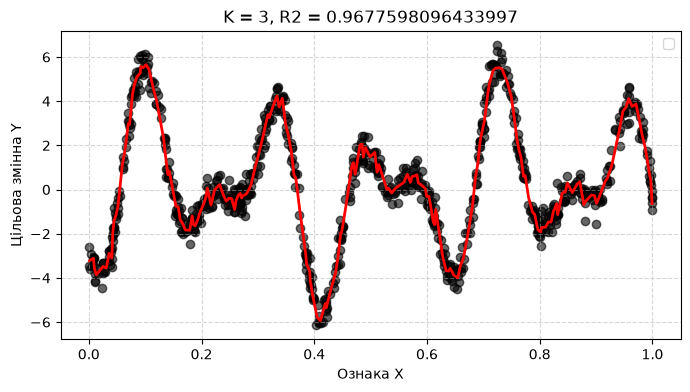

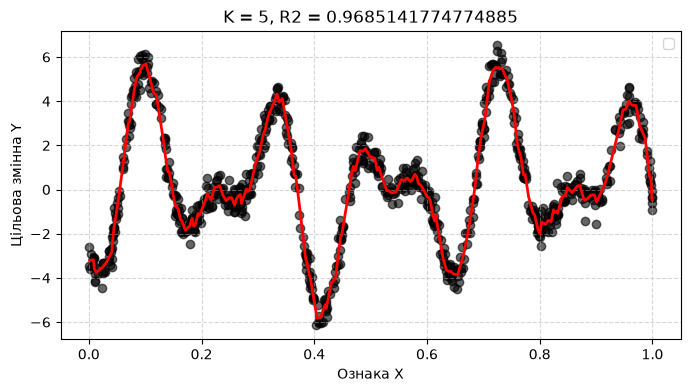

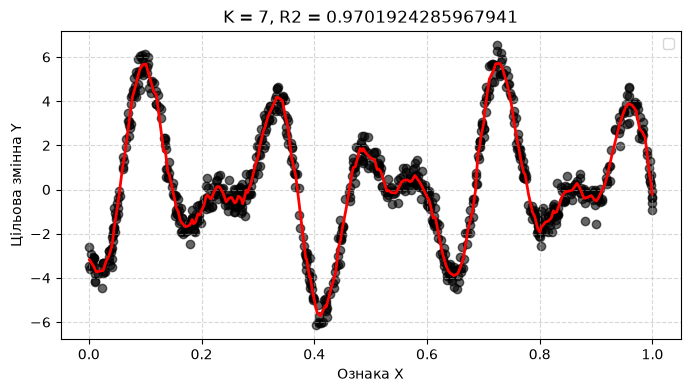

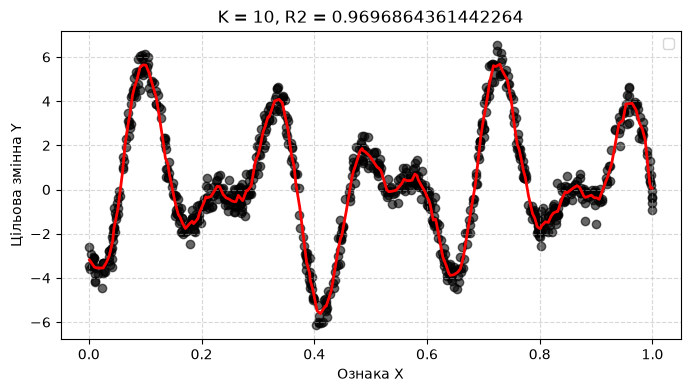

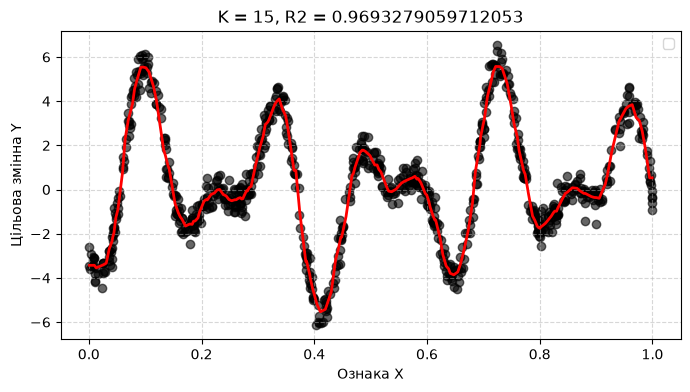

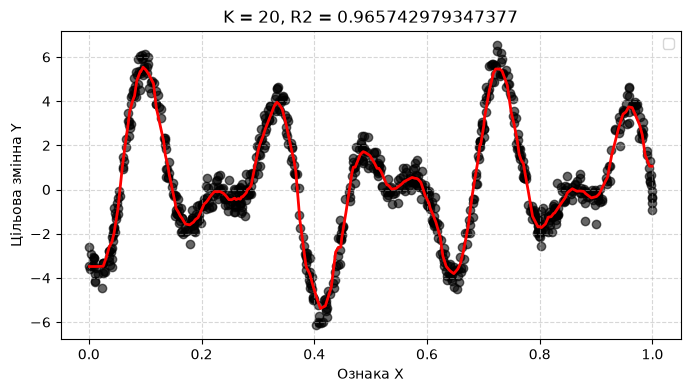

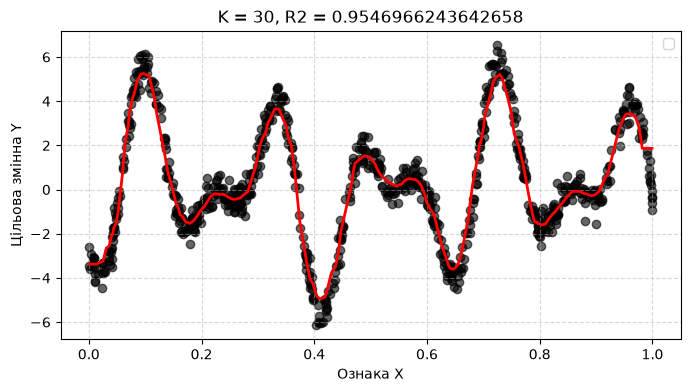

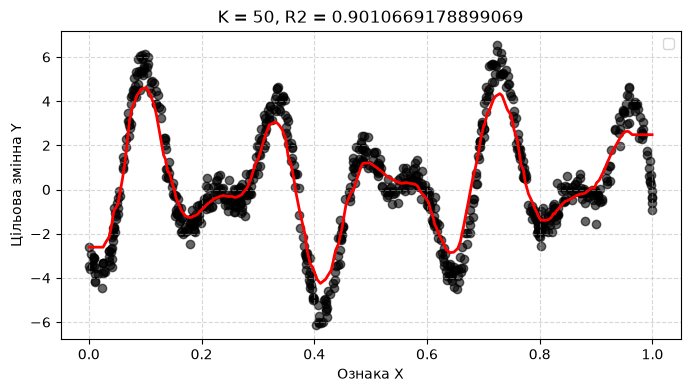

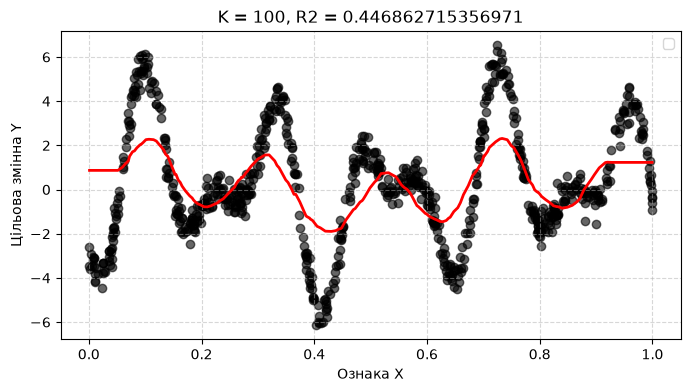

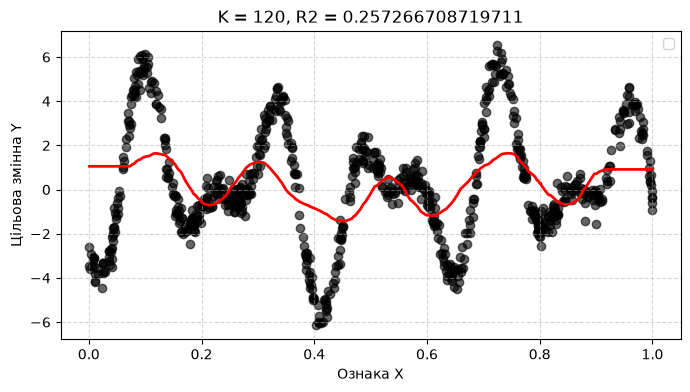

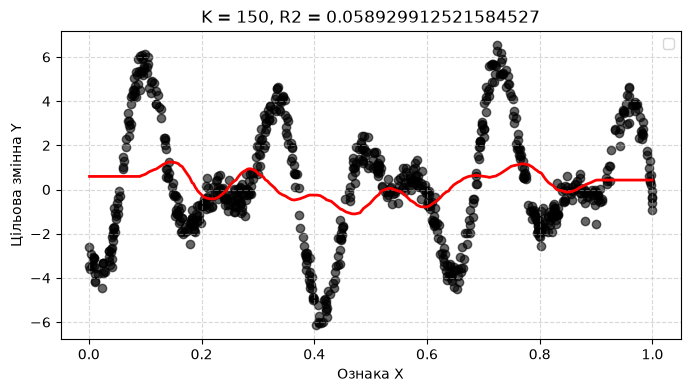

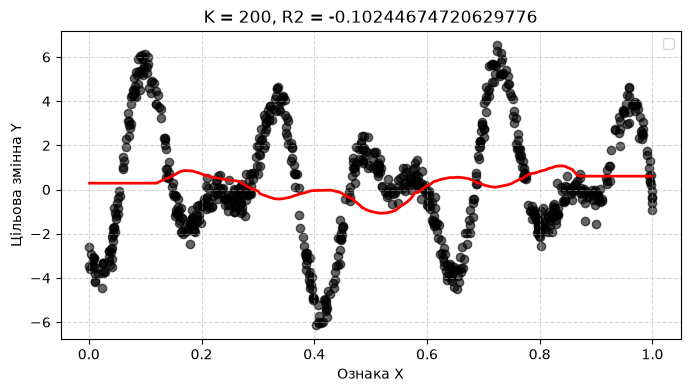

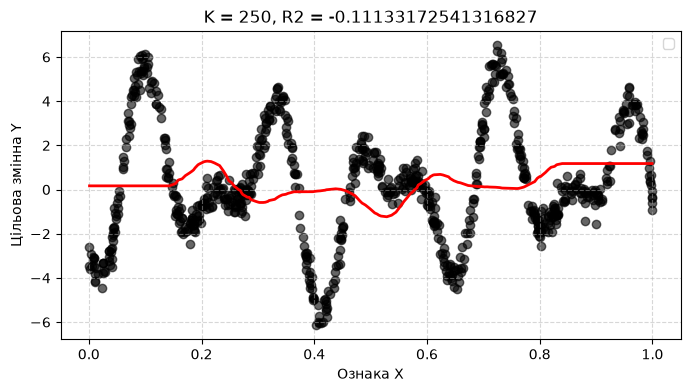

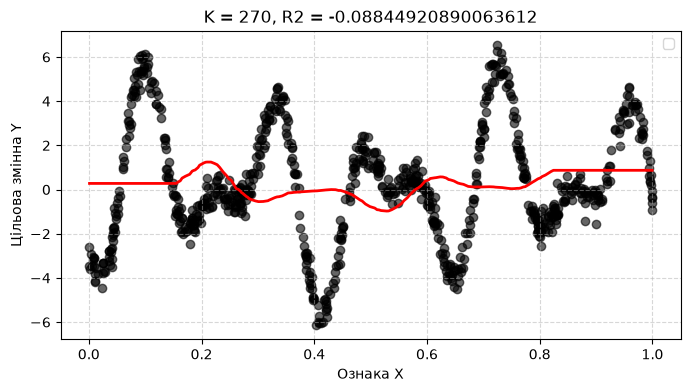

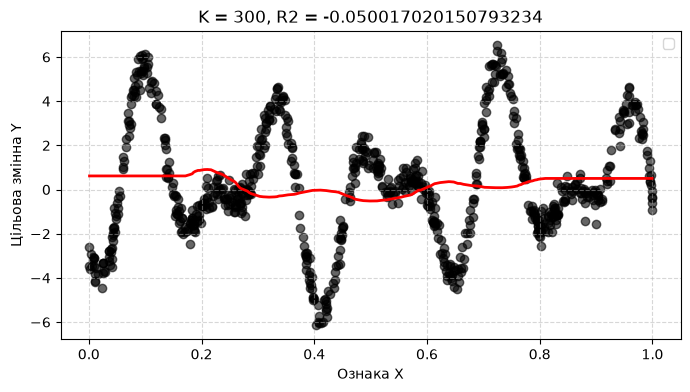

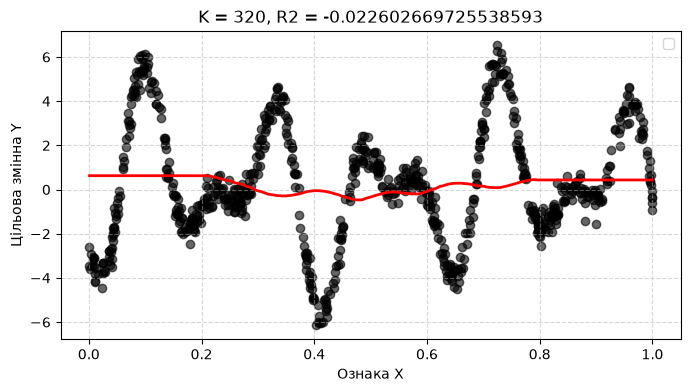

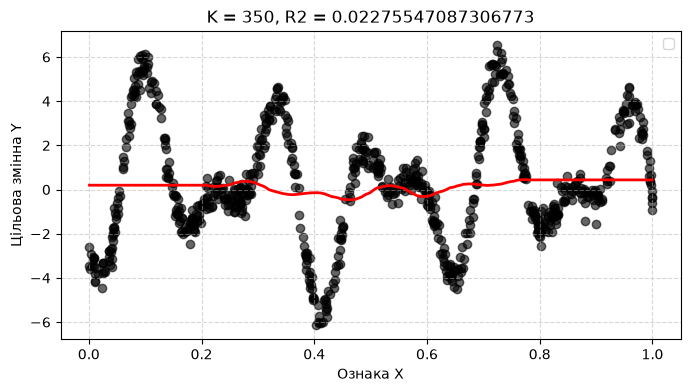

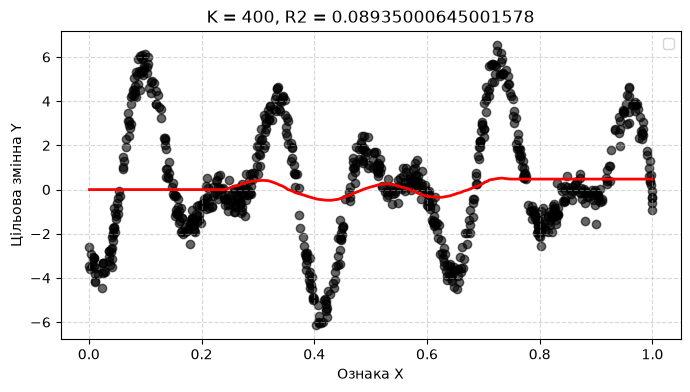

Найкращі показники якості регресії для k=7, пр цьому R2=0.9701924285967941


In [29]:
k=[3,5,7,10,15,20,30,50,100,120,150,200,250,270,300,320,350,400]
r2=[]
sstot=SStot(yTest)

# i=0
# yNew=knnArray(xLearn,yLearn,k[i],xTest)
# r2_0=R2(sstot,yNew,yTest)
# showGraph(xLearn,yLearn,xTest,yNew,k[i],r2_0)

# i+=1
# yNew=knnArray(xLearn,yLearn,k[i],xTest)
# r2_1=R2(sstot,yNew,yTest)
# showGraph(xLearn,yLearn,xTest,yNew,k[i],r2_1)

for i in range(len(k)):
    
# while(r2_1>=r2_0):
#     i+=1
#     r2_0=r2_1
    yNew = knnArray(xLearn,yLearn,k[i],xTest)
    r2_1=R2(sstot,yNew,yTest)
    showGraph(xLearn,yLearn,xTest,yNew,k[i],r2_1)
    r2.append(r2_1)
print(f"Найкращі показники якості регресії для k={k[r2.index(max(r2))]}, пр цьому R2={max(r2)}")

In [24]:
K=[]
R=[]
for k in range(2,int(0.7*n)):
    yNew=knnArray(xLearn,yLearn,k,xTest)
    r2_1=R2(sstot,yNew,yTest)
    K.append(k)
    R.append(r2_1)

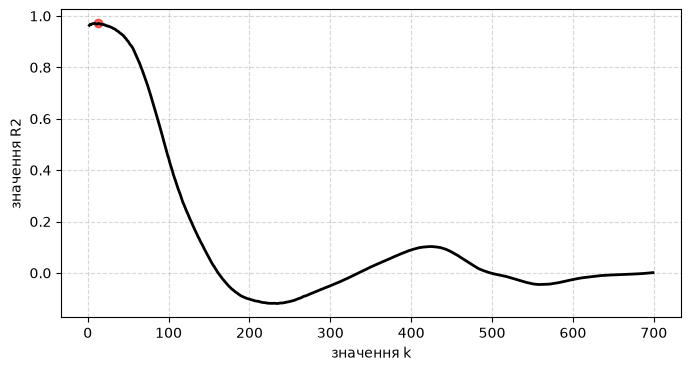

In [25]:
plt.figure(figsize=(8, 4))
plt.plot(K, R, color='black', linestyle='-', linewidth=2)
plt.scatter(K[R.index(max(R))], max(R), color='red', alpha=0.6, marker='o')
    
plt.xlabel("значення k")
plt.ylabel("значення R2")
plt.grid(True, linestyle='--', alpha=0.5)
    
plt.show()

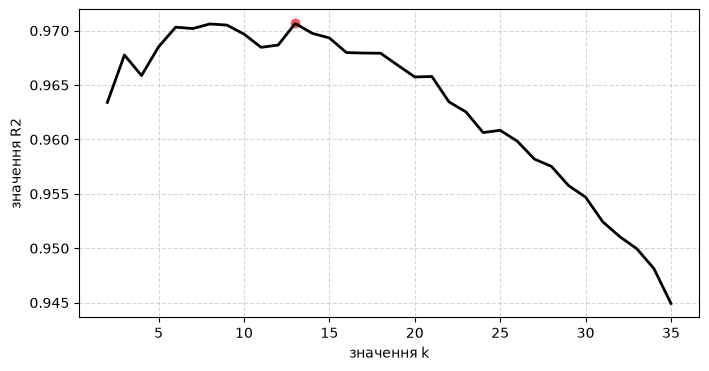

Максимальне значення R2=0.9706582014899608 при k=13


In [26]:
plt.figure(figsize=(8, 4))
plt.plot(K[0:int(0.05*len(K))], R[0:int(0.05*len(K))], color='black', linestyle='-', linewidth=2)
plt.scatter(K[R.index(max(R))], max(R), color='red', alpha=0.6, marker='o')

plt.xlabel("значення k")
plt.ylabel("значення R2")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

print(f"Максимальне значення R2={max(R)} при k={K[R.index(max(R))]}")